In [27]:
import os
import re
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import cv2

def plot_frame_strip(folder_path,offset = 0):
    """
    Plot a 1x8 strip: frame 01 + frames 11, 21, 31, 41, 51, 61 (every 10 from frame 11).
    Works with any prefix like 'xxxx01.png' where xxxx is any string.
    """
    # Find all files matching the pattern: any prefix + 2-digit number + .png
    all_files = os.listdir(folder_path)
    pattern = re.compile(r'^(.+?)(\d{2})\.png$', re.IGNORECASE)

    matches = []
    for f in all_files:
        m = pattern.match(f)
        if m:
            matches.append((m.group(1), int(m.group(2)), f))

    if not matches:
        raise FileNotFoundError("No matching files found in the folder.")

    # Determine the prefix (use the most common one if multiple exist)
    prefixes = [m[0] for m in matches]
    prefix = max(set(prefixes), key=prefixes.count)

    # Filter to only files with the chosen prefix
    filtered = {num: fname for (pfx, num, fname) in matches if pfx == prefix}

    # Target frame numbers: 01, then 11, 21, 31, 41, 51, 61
    target_frames = [1, 11, 21, 31, 41, 51, 61]

    # Load images
    images = []
    labels = []
    for num in target_frames:
        num = num-offset
        if num not in filtered:
            raise FileNotFoundError(f"Frame {num:02d} not found (expected '{prefix}{num:02d}.png')")
        img_path = os.path.join(folder_path, filtered[num])
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        # plt.imshow(img)
        images.append(img)
        labels.append(f"Frame {num:02d}")

    # Plot 1x8 grid (7 images + optional padding, or just 7 tight columns)
    fig, axes = plt.subplots(1, 7, figsize=(21, 3))
    # fig.suptitle(f"Prefix: '{prefix}' — Frame 01 + every 10th frame", fontsize=12, y=1.02)

    for ax, img, label in zip(axes, images, labels):
        ax.imshow(img,cmap = 'gray')
        # ax.set_title(label, fontsize=9)
        ax.axis('off')

    plt.tight_layout()
    plt.savefig(f"{folder_path}.png", bbox_inches='tight', dpi=150)
    plt.show()



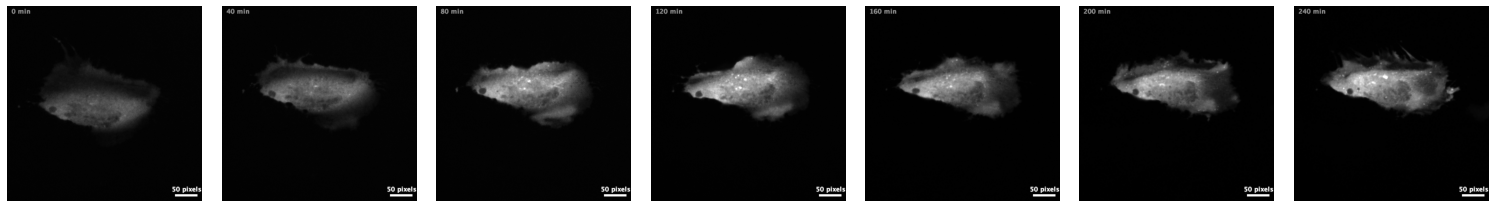

In [28]:
# --- Usage ---
plot_frame_strip("ikk-spk-1")

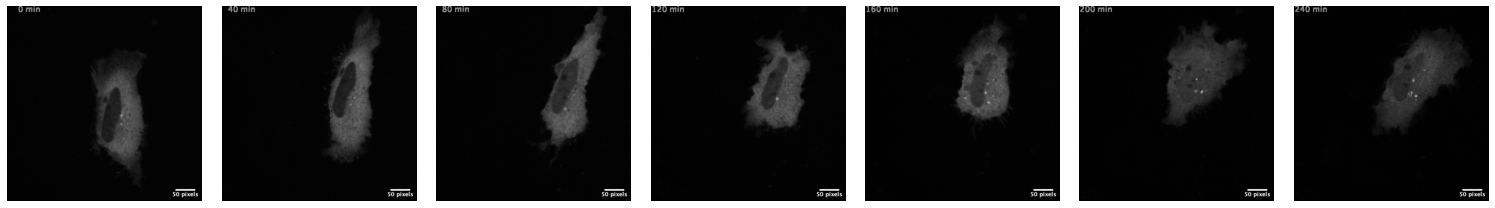

In [29]:
# --- Usage ---
plot_frame_strip("ikk-spk-novel",offset=1)

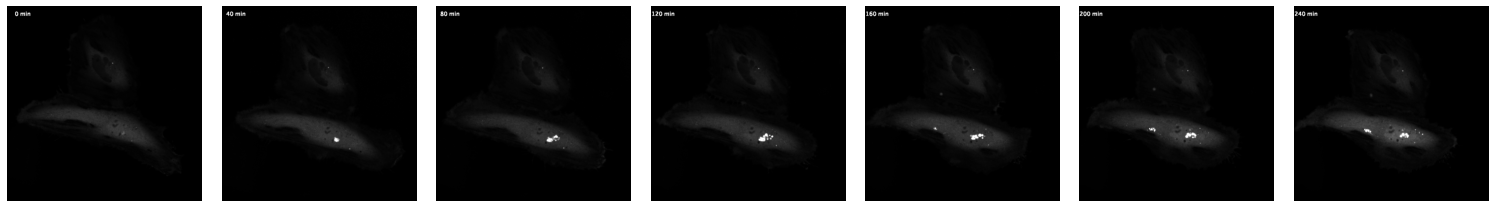

In [32]:
plot_frame_strip("tbk1-spk-1",offset=1)

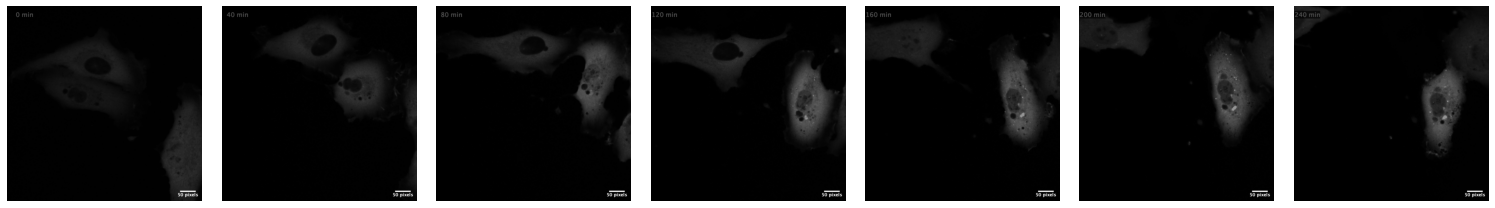

In [33]:
plot_frame_strip("tbk1-spk-novel",offset=1)

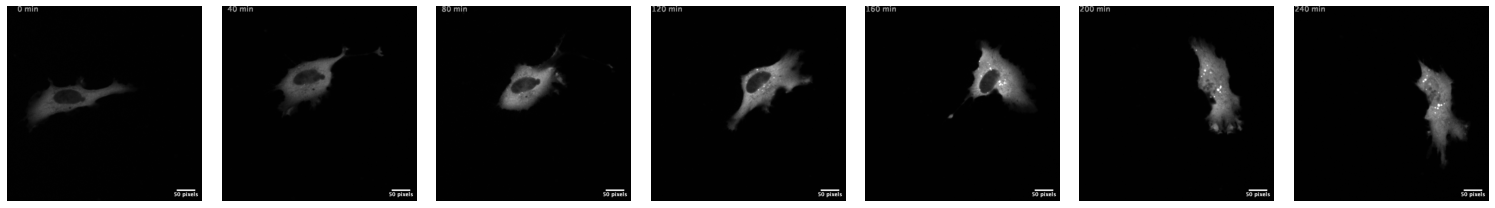

In [34]:
plot_frame_strip("tbk1-spk-novel-2",offset=1)